In [253]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
  
# Load the dataset  
df = pd.read_csv('./data/synthetic_data_169.csv')

In [254]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 8 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   location_city_tier     1000 non-null   object 
 1   room_type              1000 non-null   object 
 2   hotel_star_rating      1000 non-null   float64
 3   distance_from_airport  1000 non-null   float64
 4   season                 1000 non-null   object 
 5   number_of_amenities    1000 non-null   float64
 6   online_rating_score    1000 non-null   float64
 7   room_price_per_night   1000 non-null   float64
dtypes: float64(5), object(3)
memory usage: 62.6+ KB


### Down-sampling for faster iteration

The full data has about 1000 rows. It is small enough that no down-sampling is required for faster iteration.

In [255]:
df.head()

,location_city_tier,room_type,hotel_star_rating,distance_from_airport,season,number_of_amenities,online_rating_score,room_price_per_night
0,Tier 1,Deluxe,-0.4600,22.60,Low,7.34,8.62,159.61
1,Tier 1,Standard,0.0262,14.01,Low,5.18,8.09,165.93
2,Tier 1,Standard,-0.1920,15.25,High,8.93,8.50,183.08
3,Tier 1,Standard,0.4590,27.98,Shoulder,7.13,8.77,192.74
4,Tier 3,Standard,0.7080,22.48,High,8.90,9.52,212.04


In [256]:
df.isnull().sum()

location_city_tier       0
room_type                0
hotel_star_rating        0
distance_from_airport    0
season                   0
number_of_amenities      0
online_rating_score      0
room_price_per_night     0
dtype: int64

In [257]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
hotel_star_rating,1000.0,-0.018365,0.980771,-2.86,-0.66575,-0.0207,0.62675,3.52
distance_from_airport,1000.0,14.773790,7.654063,3.50,9.41000,13.0550,17.97750,60.75
number_of_amenities,1000.0,7.877448,2.986685,-1.60,5.91750,7.8700,9.77000,17.55
online_rating_score,1000.0,8.970650,0.621903,6.19,8.60000,9.0600,9.47000,9.96
room_price_per_night,1000.0,209.853450,66.831272,85.66,163.23500,196.2950,239.81250,523.82


In [258]:
df.duplicated().sum()

0

**What the initial exploration shows**

- **Size and types:** 1000 rows and 8 columns. 5 columns are numeric and 3 are text. The target is `room_price_per_night`.
- **Missing values:** None
- **Implausible values:** negative values for `hotel_star_rating` and `number_of_amenities`
- **Duplicates** None

Creating Bar Chart
---------

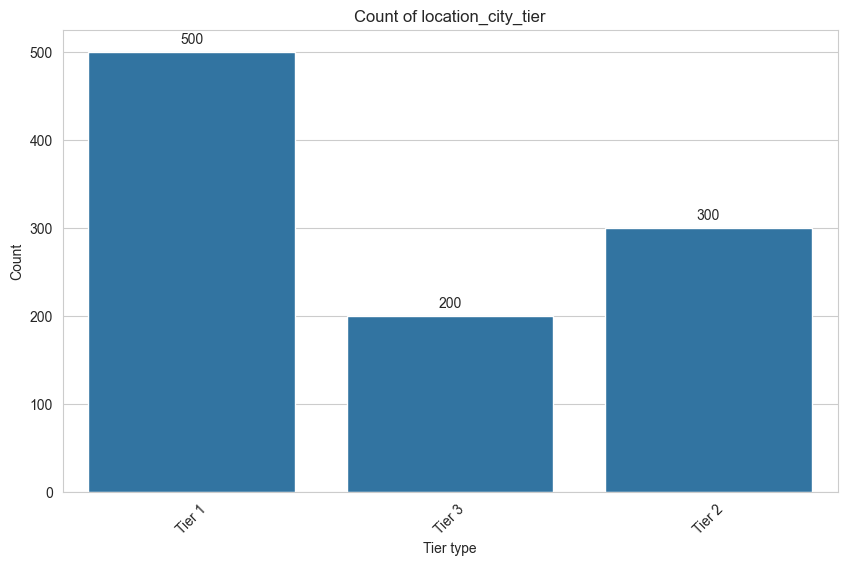

In [259]:
# Set the aesthetic style of the plots
sns.set_style("whitegrid")

# Bar chart for location_city_tier with annotations
plt.figure(figsize=(10, 6))
count_plot = sns.countplot(x='location_city_tier', data=df)
plt.title('Count of location_city_tier')
plt.xlabel('Tier type')
plt.ylabel('Count')
plt.xticks(rotation=45)

# Annotate the bars with the frequency count
for p in count_plot.patches:
    count_plot.annotate(format(p.get_height(), '.0f'),
                        (p.get_x() + p.get_width() / 2., p.get_height()),
                        ha = 'center', va = 'center',
                        xytext = (0, 9),
                        textcoords = 'offset points')

plt.show()

- Tier 1 is most common (50%)

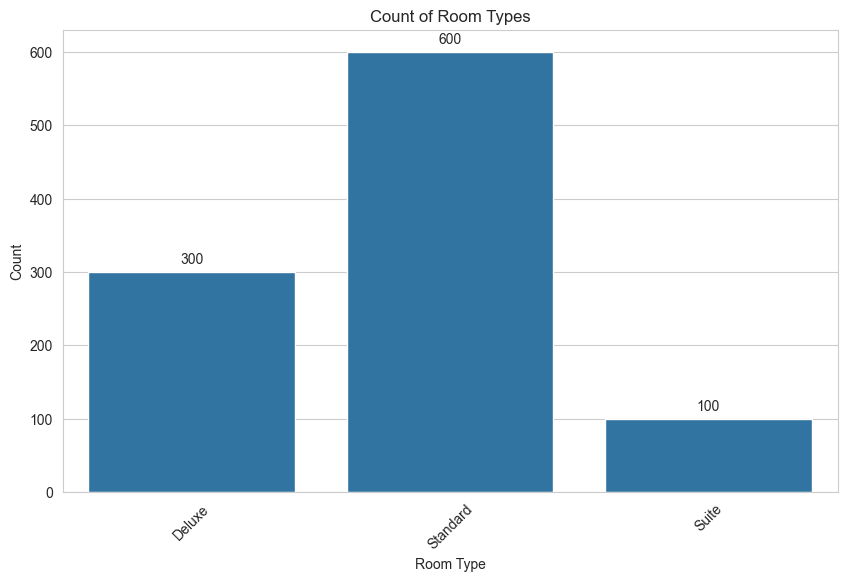

In [260]:
# Set the aesthetic style of the plots
sns.set_style("whitegrid")

# Bar chart for room type with annotations
plt.figure(figsize=(10, 6))
count_plot = sns.countplot(x='room_type', data=df)
plt.title('Count of Room Types')
plt.xlabel('Room Type')
plt.ylabel('Count')
plt.xticks(rotation=45)

# Annotate the bars with the frequency count
for p in count_plot.patches:
    count_plot.annotate(format(p.get_height(), '.0f'),
                        (p.get_x() + p.get_width() / 2., p.get_height()),
                        ha = 'center', va = 'center',
                        xytext = (0, 9),
                        textcoords = 'offset points')

plt.show()

- Standard is most common (60%)

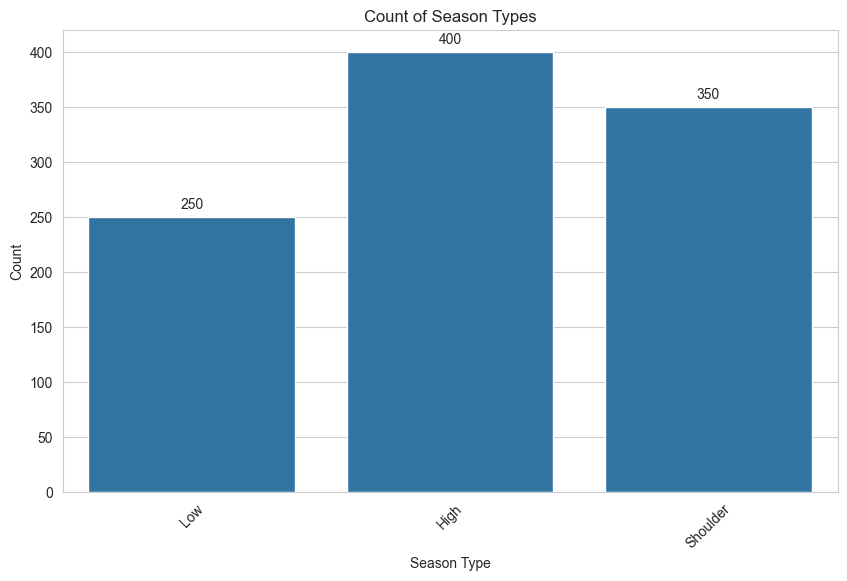

In [261]:
# Set the aesthetic style of the plots
sns.set_style("whitegrid")

# Bar chart for season with annotations
plt.figure(figsize=(10, 6))
count_plot = sns.countplot(x='season', data=df)
plt.title('Count of Season Types')
plt.xlabel('Season Type')
plt.ylabel('Count')
plt.xticks(rotation=45)

# Annotate the bars with the frequency count
for p in count_plot.patches:
    count_plot.annotate(format(p.get_height(), '.0f'),
                        (p.get_x() + p.get_width() / 2., p.get_height()),
                        ha = 'center', va = 'center',
                        xytext = (0, 9),
                        textcoords = 'offset points')

plt.show()

- High season is most common

Creating Histogram
------------------

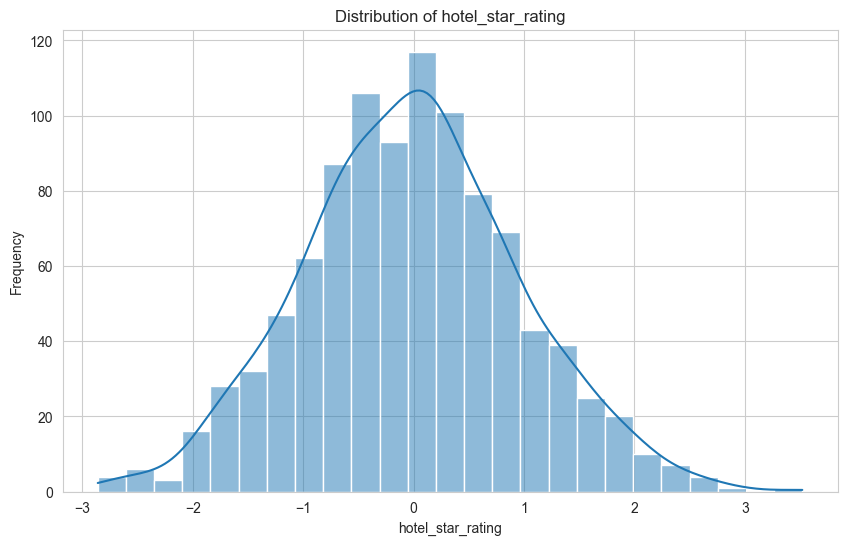

In [262]:
# Set the aesthetic style of the plots  
sns.set_style("whitegrid")  
  
# Histogram for price  
plt.figure(figsize=(10, 6))  
sns.histplot(df['hotel_star_rating'], kde=True)  
plt.title('Distribution of hotel_star_rating')  
plt.xlabel('hotel_star_rating')  
plt.ylabel('Frequency')  
plt.show()

- negative values for hotel_star_rating
- appears pre-standardized with z-score transformation (mean ≈ 0, std ≈ 1)

In [263]:
col = df['hotel_star_rating']
print(f"mean={col.mean():.3f}, std={col.std():.3f}, min={col.min():.2f}, max={col.max():.2f}, skew={col.skew():.2f}")

mean=-0.018, std=0.981, min=-2.86, max=3.52, skew=0.10


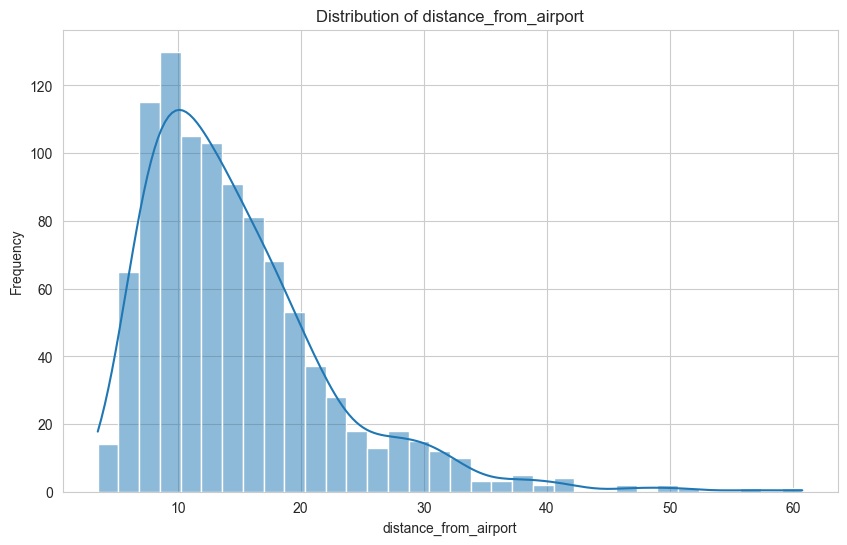

In [264]:
# Set the aesthetic style of the plots  
sns.set_style("whitegrid")  
  
# Histogram for price  
plt.figure(figsize=(10, 6))  
sns.histplot(df['distance_from_airport'], kde=True)  
plt.title('Distribution of distance_from_airport')  
plt.xlabel('distance_from_airport')  
plt.ylabel('Frequency')  
plt.show()

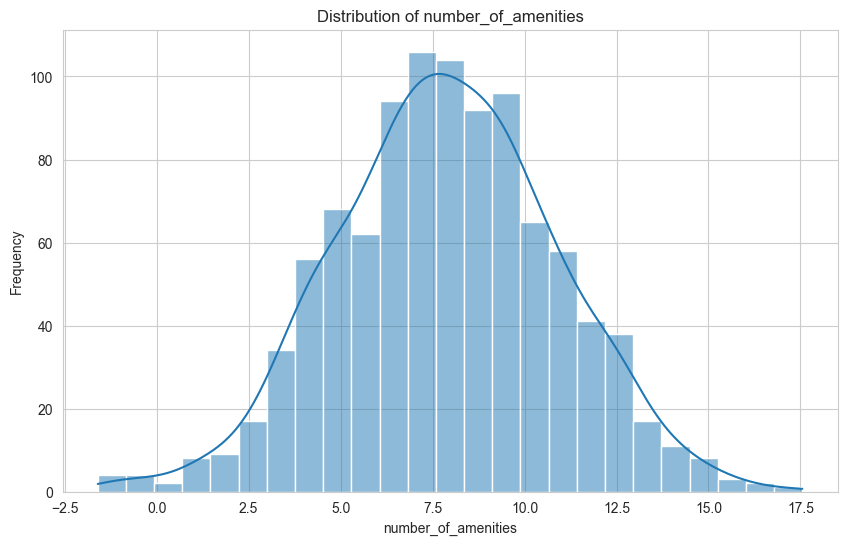

In [265]:
# Set the aesthetic style of the plots  
sns.set_style("whitegrid")  
  
# Histogram for price  
plt.figure(figsize=(10, 6))  
sns.histplot(df['number_of_amenities'], kde=True)  
plt.title('Distribution of number_of_amenities')  
plt.xlabel('number_of_amenities')  
plt.ylabel('Frequency')  
plt.show()

- negative values for number_of_amenities

In [266]:
neg_amenities = df[df['number_of_amenities'] < 0]
print(f"Rows with negative number_of_amenities: {len(neg_amenities)}")
neg_amenities

Rows with negative number_of_amenities: 8


,location_city_tier,room_type,hotel_star_rating,distance_from_airport,season,number_of_amenities,online_rating_score,room_price_per_night
171,Tier 3,Deluxe,-2.54,31.51,Shoulder,-1.050,6.98,85.66
200,Tier 3,Deluxe,-1.71,16.65,Low,-0.250,7.71,119.60
404,Tier 1,Suite,-1.77,27.65,Low,-1.600,7.23,100.72
578,Tier 2,Suite,-1.74,15.97,High,-0.227,8.18,145.16
722,Tier 2,Standard,-2.44,19.88,Low,-1.280,7.75,118.91
738,Tier 3,Deluxe,-2.76,20.95,Shoulder,-0.993,6.86,103.67
754,Tier 3,Deluxe,-1.42,41.63,High,-0.154,8.14,119.20
962,Tier 3,Deluxe,-2.61,20.19,High,-0.702,6.69,97.33


- 8 negative rows, with values between −1.6 and −0.15. A count of amenities can’t be negative, so most likely noise in a column whose true value is low, near 0. Prices back this up.
- 8 negative rows have a mean price of about 111, against an overall mean of about 210 and include some of the cheapest rooms in the dataset (85.66, 97.33, 100.72).

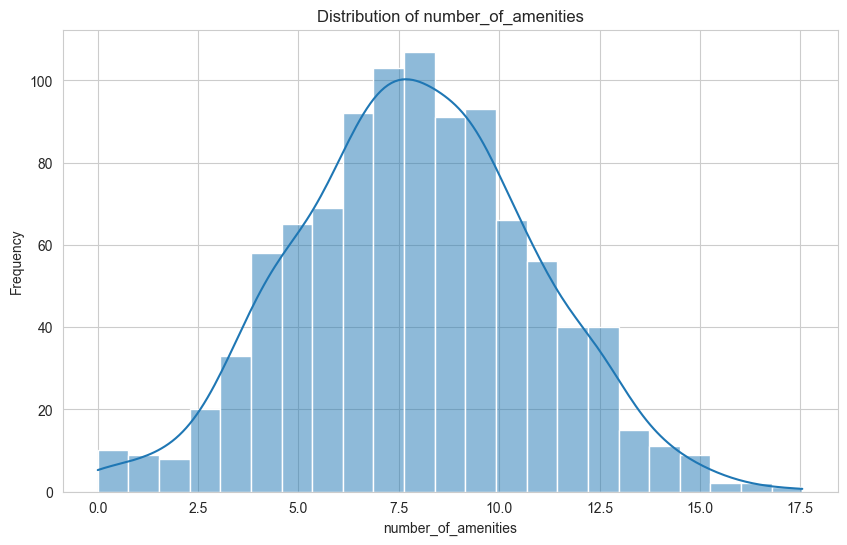

In [267]:
df['number_of_amenities'] = df['number_of_amenities'].clip(lower=0)  

# Set the aesthetic style of the plots  
sns.set_style("whitegrid")  
  
# Histogram for price  
plt.figure(figsize=(10, 6))  
sns.histplot(df['number_of_amenities'], kde=True)  
plt.title('Distribution of number_of_amenities')  
plt.xlabel('number_of_amenities')  
plt.ylabel('Frequency')  
plt.show()

- Normal distribution of counts for number_of_amenities

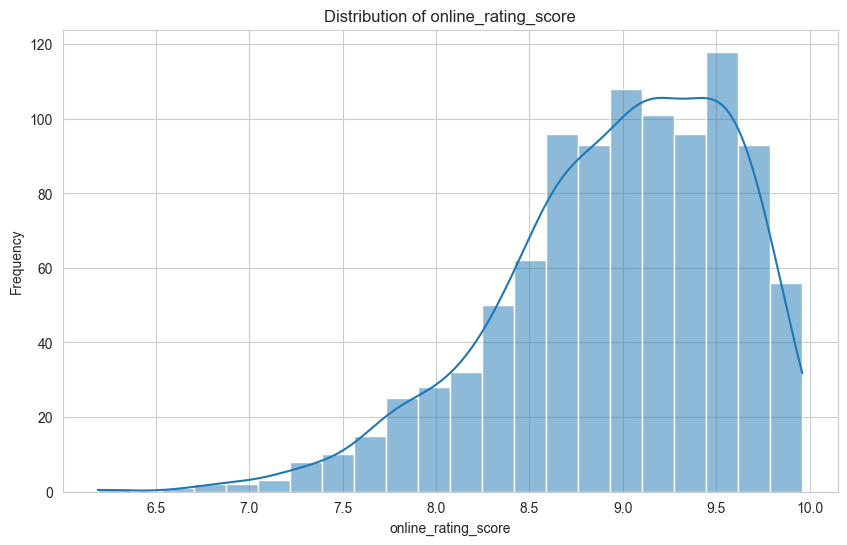

In [268]:
# Set the aesthetic style of the plots  
sns.set_style("whitegrid")  
  
# Histogram for price  
plt.figure(figsize=(10, 6))  
sns.histplot(df['online_rating_score'], kde=True)  
plt.title('Distribution of online_rating_score')  
plt.xlabel('online_rating_score')  
plt.ylabel('Frequency')  
plt.show()

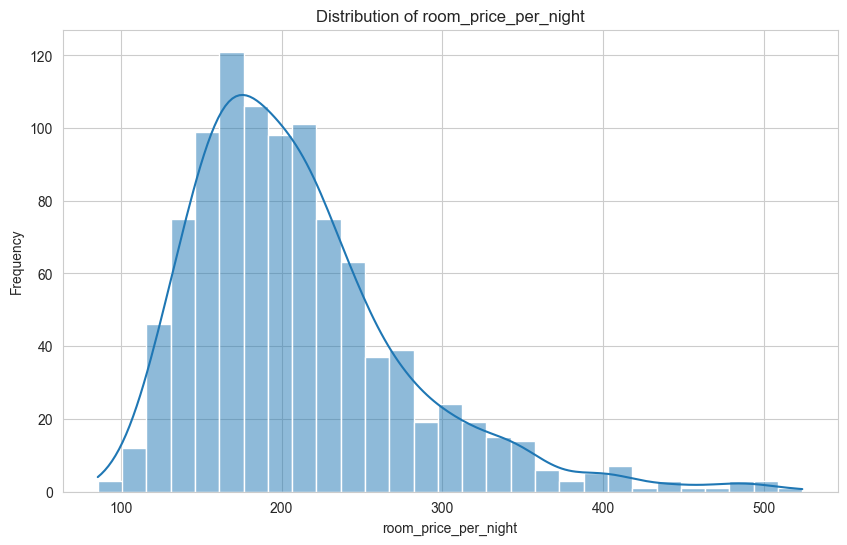

In [269]:
# Set the aesthetic style of the plots  
sns.set_style("whitegrid")  
  
# Histogram for price  
plt.figure(figsize=(10, 6))  
sns.histplot(df['room_price_per_night'], kde=True)  
plt.title('Distribution of room_price_per_night')  
plt.xlabel('room_price_per_night')  
plt.ylabel('Frequency')  
plt.show()

Creating Line Chart
-------------------

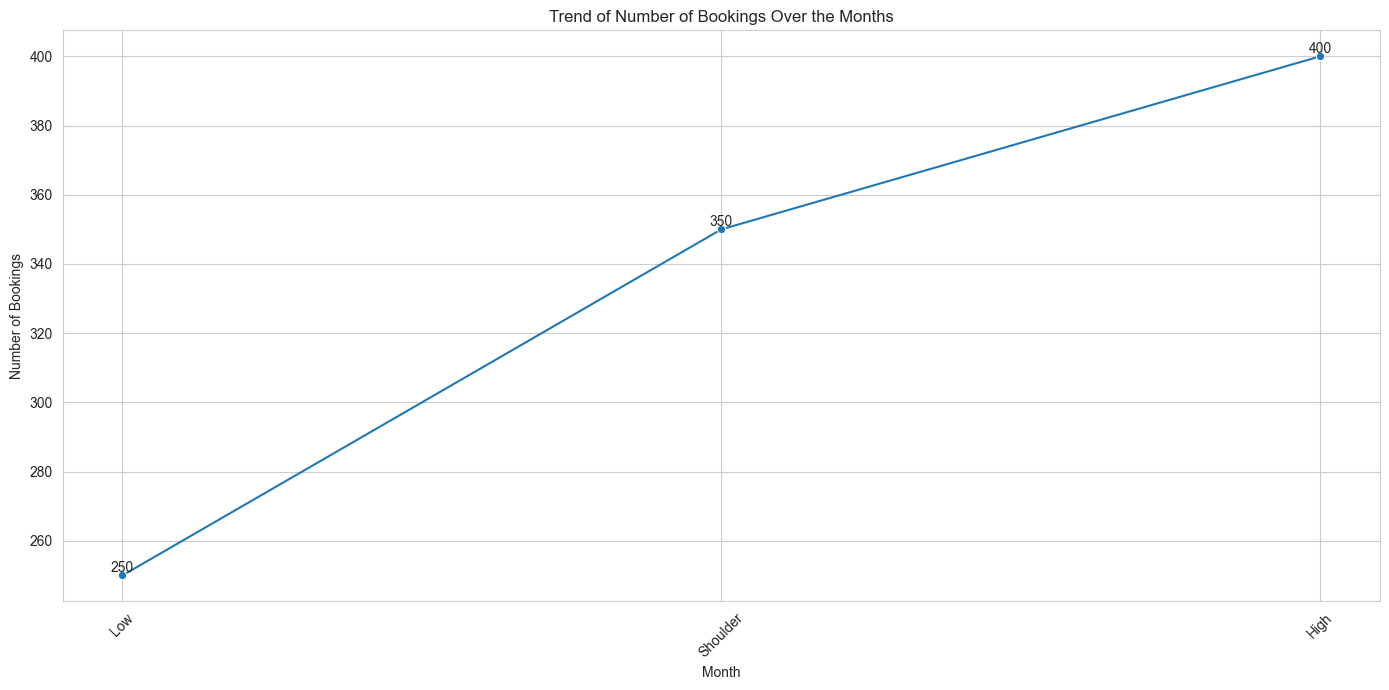

In [270]:
# Set Aesthetic Style
sns.set_style("whitegrid")

# Count the Number of Bookings by season
month_order = ['Low', 'Shoulder', 'High']
month_counts = df['season'].value_counts().reindex(month_order)

# Create the Line Chart
plt.figure(figsize=(14, 7))
line_plot = sns.lineplot(x=month_counts.index, y=month_counts.values, marker='o')

# Annotate the Data Points
for x, y in zip(month_counts.index, month_counts.values):
    plt.text(x, y, f'{y}', ha='center', va='bottom')

# Label the Chart
plt.title('Trend of Number of Bookings Over the Months')
plt.xlabel('Month')
plt.ylabel('Number of Bookings')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

- Similar to bar chart, High season is most common

Creating a Box Plot
---------------------------

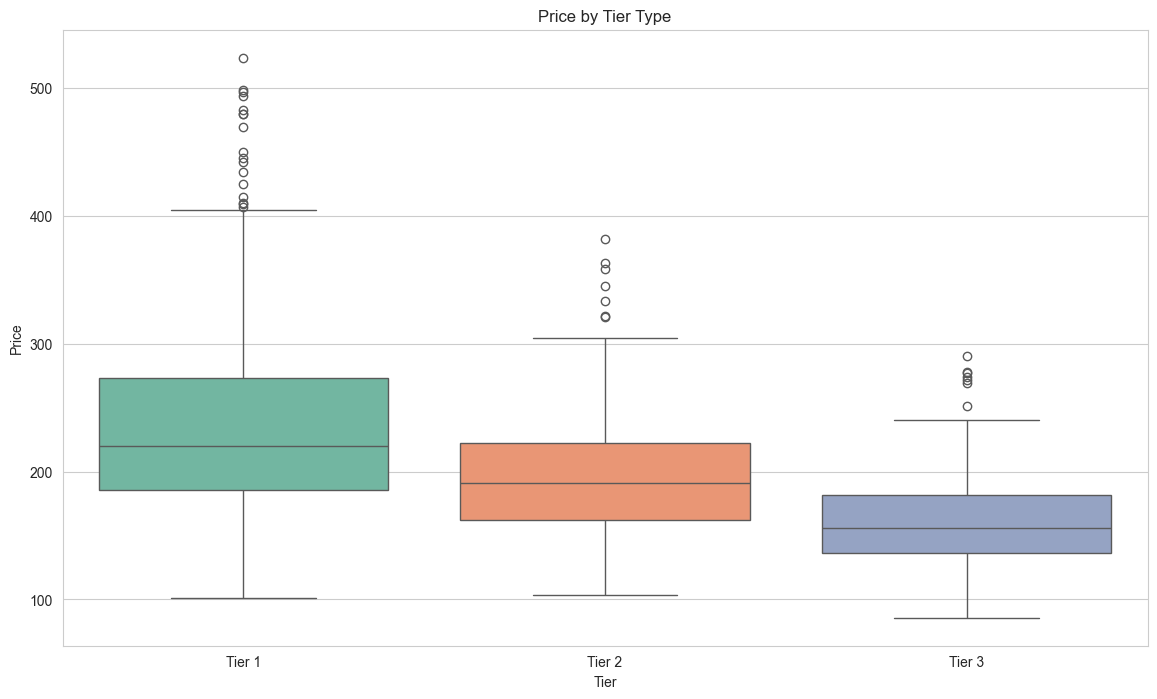

In [271]:
# Set the aesthetic style of the plots
sns.set_style("whitegrid")
location_city_tier_order = ['Tier 1', 'Tier 2', 'Tier 3']

# Box plot for tier vs price
plt.figure(figsize=(14, 8))
sns.boxplot(x='location_city_tier', y='room_price_per_night', data=df, order=location_city_tier_order,
            hue='location_city_tier', hue_order=location_city_tier_order, palette='Set2', legend=False)
plt.title('Price by Tier Type')
plt.xlabel('Tier')
plt.ylabel('Price')
plt.xticks(rotation=0)
plt.show()

- Price decreases with higher Tier number
- Median price decreases with higher Tier number
- IQR is smallest for Tier 3, suggesting more consistent pricing
- IQR is largest for Tier 1, suggesting greater variability in prices
- Presence of outliers for all Tiers

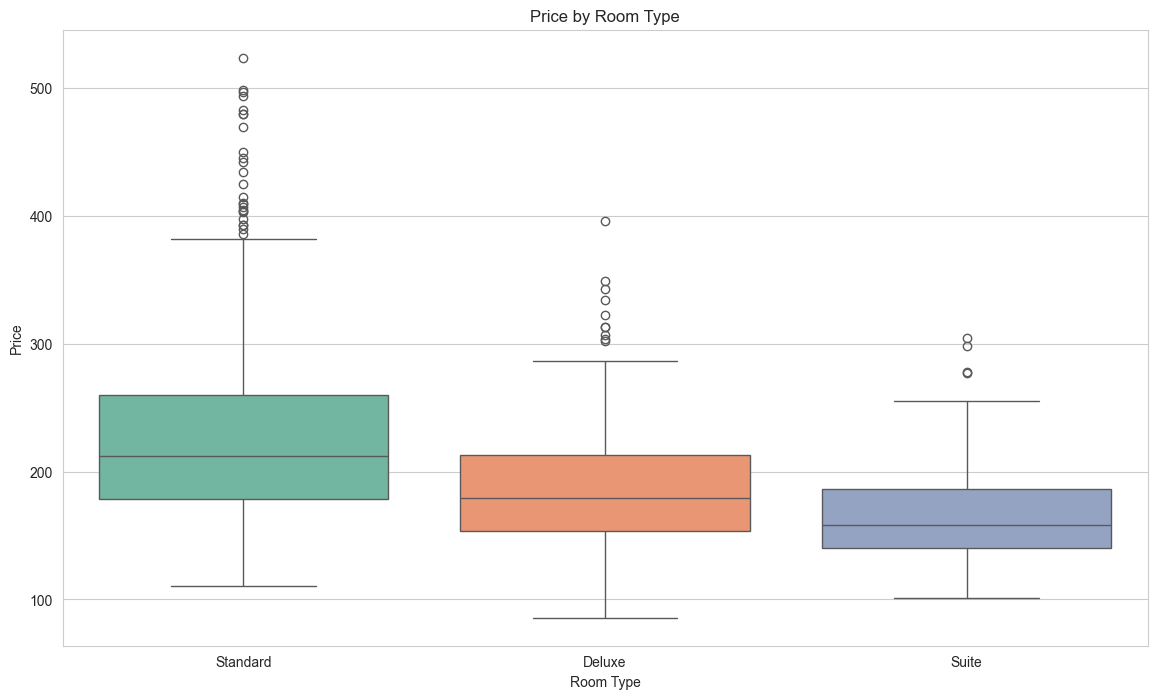

In [272]:
# Set the aesthetic style of the plots
sns.set_style("whitegrid")
room_type_order = ['Standard', 'Deluxe', 'Suite']

# Box plot for room vs price
plt.figure(figsize=(14, 8))
sns.boxplot(x='room_type', y='room_price_per_night', data=df, order=room_type_order,
            hue='room_type', hue_order=room_type_order, palette='Set2', legend=False)
plt.title('Price by Room Type')
plt.xlabel('Room Type')
plt.ylabel('Price')
plt.xticks(rotation=0)
plt.show()

- Price decreases with Standard > Deluxe > Suite
- Median price decreases with Standard > Deluxe > Suite
- IQR is smallest for Suite, suggesting more consistent pricing
- IQR is largest for Standard, suggesting greater variability in prices
- Presence of outliers for all room types
- To cast room_type as nominal instead of ordinal due to contradictory room_type and price relationship

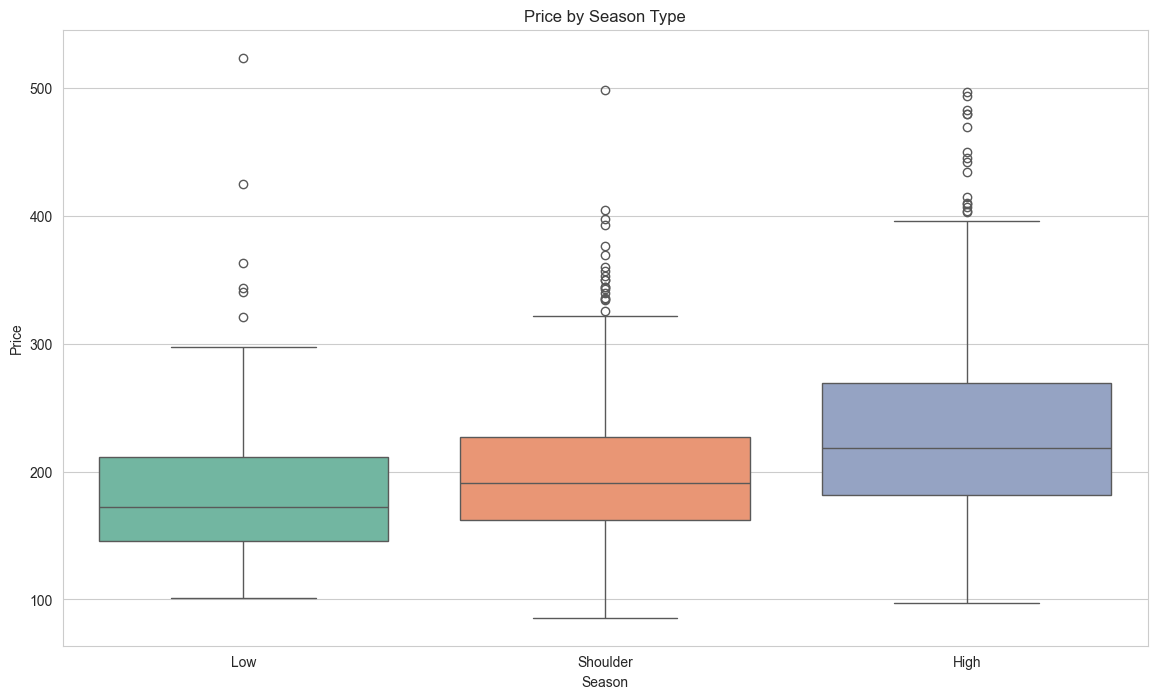

In [273]:
# Set the aesthetic style of the plots
sns.set_style("whitegrid")
season_order = ['Low', 'Shoulder', 'High']

# Box plot for season vs price
plt.figure(figsize=(14, 8))
sns.boxplot(x='season', y='room_price_per_night', data=df, order=season_order,
            hue='season', hue_order=season_order, palette='Set2', legend=False)
plt.title('Price by Season Type')
plt.xlabel('Season')
plt.ylabel('Price')
plt.xticks(rotation=0)
plt.show()

- Price increases with busier season
- Median price increases with busier season
- IQR is smallest for low season, suggesting more consistent pricing
- IQR is largest for high season, suggesting greater variability in prices
- Presence of outliers for all seasons

Creating a Scatter Plot
---------------------------

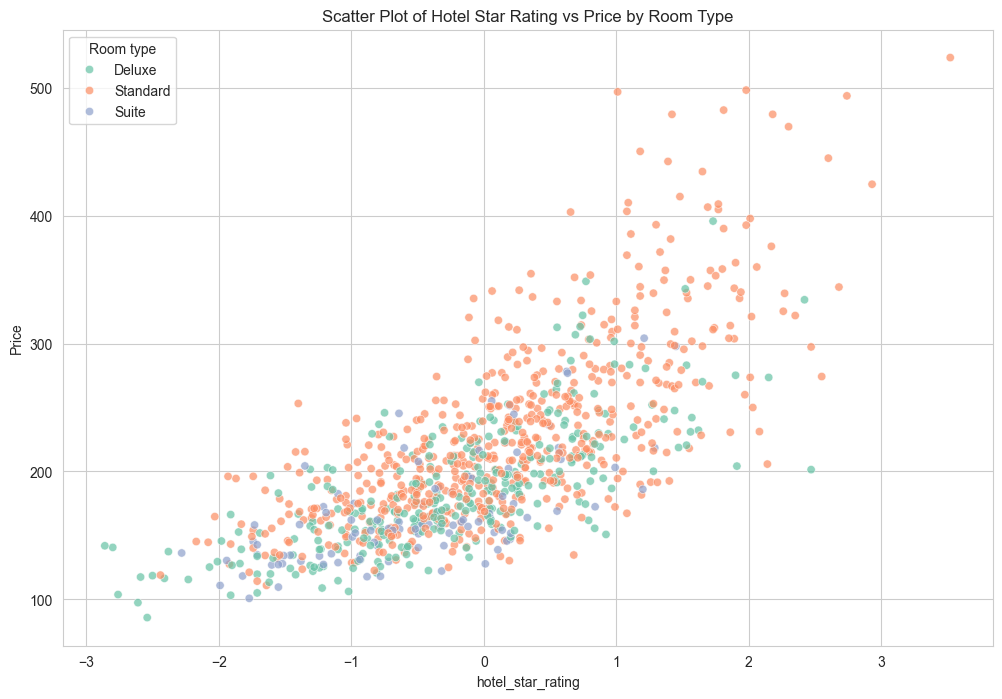

In [274]:
# Set the aesthetic style of the plots
sns.set_style("whitegrid")

# Scatter plot for floor area vs resale price with color encoding for flat type
plt.figure(figsize=(12, 8))
sns.scatterplot(x='hotel_star_rating', y='room_price_per_night', hue='room_type', data=df, palette='Set2', alpha=0.7)
plt.title('Scatter Plot of Hotel Star Rating vs Price by Room Type')
plt.xlabel('hotel_star_rating')
plt.ylabel('Price')
plt.legend(title='Room type')
plt.show()

- Positive trend as Hotel Star Rating increases, room price per night increases
- No clear room type distinction, though most room prices above 400 is 'Standard'
- Wider spread of room price per night for as hotel star rating increases
- Outliers are all 'Standard' room type at significant higher prices compared to others with similar number of amentities

In [275]:
# Filter the data for outliers
outliers = df[(df['room_type'] == 'Standard') & 
                        (df['hotel_star_rating'] > 0) & 
                        (df['room_price_per_night'] > 400)]

# Display the outliers
outliers

,location_city_tier,room_type,hotel_star_rating,distance_from_airport,season,number_of_amenities,online_rating_score,room_price_per_night
31,Tier 1,Standard,1.810,14.88,High,13.24,9.95,482.74
140,Tier 1,Standard,1.770,26.42,Shoulder,12.22,9.94,404.98
175,Tier 1,Standard,1.770,6.41,High,13.06,9.56,409.20
184,Tier 1,Standard,2.180,9.89,High,15.37,9.60,479.43
194,Tier 1,Standard,3.520,11.03,Low,16.12,9.95,523.82
261,Tier 1,Standard,1.090,9.38,High,12.56,9.96,410.29
286,Tier 1,Standard,1.650,22.29,High,15.68,9.68,434.63
298,Tier 1,Standard,1.480,14.46,High,10.38,9.66,415.05
340,Tier 1,Standard,1.690,13.85,High,13.67,9.81,406.82
353,Tier 1,Standard,1.420,8.30,High,12.12,9.93,479.40


- High hotel star rating, Tier 1 location, high online score seems plausible to explain high room price per night
- All are Tier 1 Standard room types with mostly in high season
- For low and shoulder season, high hotel star rating, or high online rating store could explain for high room price per night

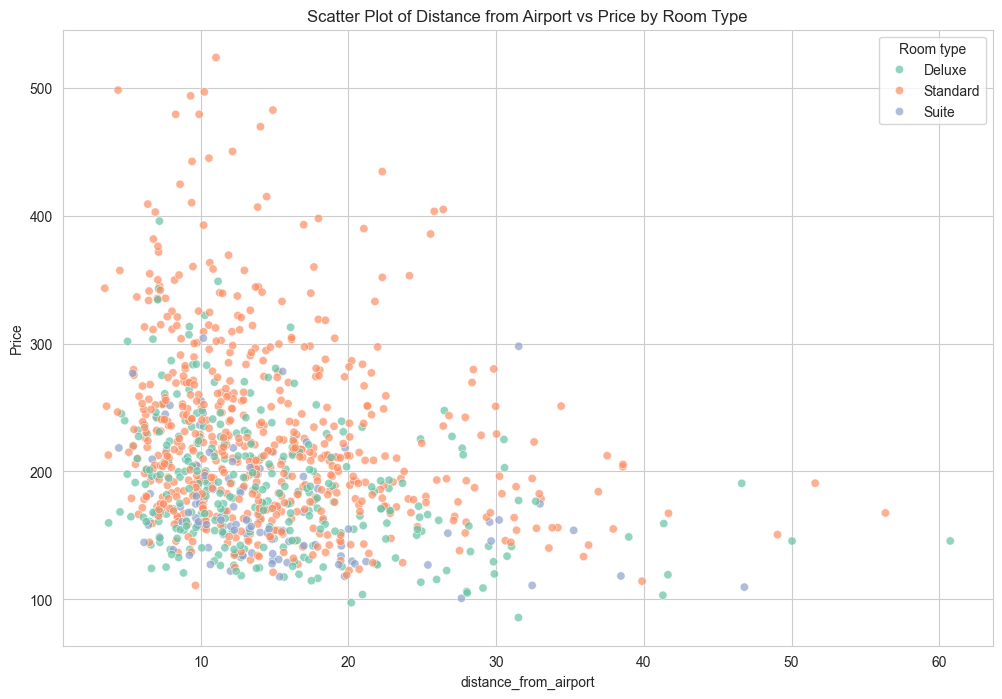

In [276]:
# Set the aesthetic style of the plots
sns.set_style("whitegrid")

plt.figure(figsize=(12, 8))
sns.scatterplot(x='distance_from_airport', y='room_price_per_night', hue='room_type', data=df, palette='Set2', alpha=0.7)
plt.title('Scatter Plot of Distance from Airport vs Price by Room Type')
plt.xlabel('distance_from_airport')
plt.ylabel('Price')
plt.legend(title='Room type')
plt.show()

- Weak negative trend between Distance from Airport vs room price per night
- No clear room type distinction, though most room prices above 300 is 'Standard'
- Narrower spread of room price per night for as distance from airport increases
- Outliers at significant higher prices compared to others with similar distance from airport

In [277]:
# Filter the data for outliers
outliers = df[(df['room_type'] == 'Standard') & 
                        (df['distance_from_airport'] < 30) & 
                        (df['room_price_per_night'] > 400)]

# Display the outliers
outliers

,location_city_tier,room_type,hotel_star_rating,distance_from_airport,season,number_of_amenities,online_rating_score,room_price_per_night
31,Tier 1,Standard,1.810,14.88,High,13.24,9.95,482.74
140,Tier 1,Standard,1.770,26.42,Shoulder,12.22,9.94,404.98
175,Tier 1,Standard,1.770,6.41,High,13.06,9.56,409.20
184,Tier 1,Standard,2.180,9.89,High,15.37,9.60,479.43
194,Tier 1,Standard,3.520,11.03,Low,16.12,9.95,523.82
261,Tier 1,Standard,1.090,9.38,High,12.56,9.96,410.29
286,Tier 1,Standard,1.650,22.29,High,15.68,9.68,434.63
298,Tier 1,Standard,1.480,14.46,High,10.38,9.66,415.05
340,Tier 1,Standard,1.690,13.85,High,13.67,9.81,406.82
353,Tier 1,Standard,1.420,8.30,High,12.12,9.93,479.40


- All are Tier 1 Standard room types with mostly in high season
- For low and shoulder season, high hotel star rating, online rating store, number of amentities could explain for high room price per night

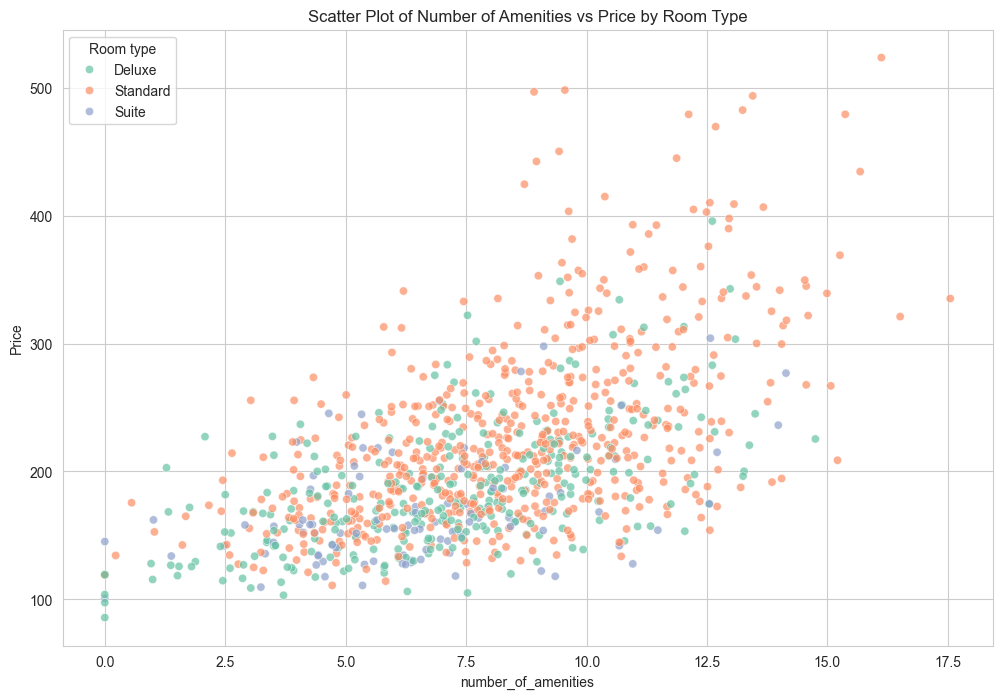

In [278]:
# Set the aesthetic style of the plots
sns.set_style("whitegrid")

plt.figure(figsize=(12, 8))
sns.scatterplot(x='number_of_amenities', y='room_price_per_night', hue='room_type', data=df, palette='Set2', alpha=0.7)
plt.title('Scatter Plot of Number of Amenities vs Price by Room Type')
plt.xlabel('number_of_amenities')
plt.ylabel('Price')
plt.legend(title='Room type')
plt.show()

- Positive trend as number of amentities increases, room price per night increases
- No clear room type distinction, though most room prices > 300 is 'Standard'
- Wider spread of room price per night as number of amentities increases
- Outliers are all 'Standard' room type at significant higher prices compared to others with similar number of amentities

In [279]:
# Filter the data for outliers
outliers = df[(df['room_type'] == 'Standard') & 
                        (df['number_of_amenities'] > 7.5) & 
                        (df['room_price_per_night'] > 400)]

# Display the outliers
outliers

,location_city_tier,room_type,hotel_star_rating,distance_from_airport,season,number_of_amenities,online_rating_score,room_price_per_night
31,Tier 1,Standard,1.810,14.88,High,13.24,9.95,482.74
140,Tier 1,Standard,1.770,26.42,Shoulder,12.22,9.94,404.98
175,Tier 1,Standard,1.770,6.41,High,13.06,9.56,409.20
184,Tier 1,Standard,2.180,9.89,High,15.37,9.60,479.43
194,Tier 1,Standard,3.520,11.03,Low,16.12,9.95,523.82
261,Tier 1,Standard,1.090,9.38,High,12.56,9.96,410.29
286,Tier 1,Standard,1.650,22.29,High,15.68,9.68,434.63
298,Tier 1,Standard,1.480,14.46,High,10.38,9.66,415.05
340,Tier 1,Standard,1.690,13.85,High,13.67,9.81,406.82
353,Tier 1,Standard,1.420,8.30,High,12.12,9.93,479.40


- All are Tier 1 Standard room types with mostly in high season
- For low and shoulder season, high hotel star rating, online rating store, number of amentities could explain for high room price per night

In [280]:
# Filter the data for outliers
outliers = df[(df['room_type'] == 'Standard') & 
                        (df['number_of_amenities'] > 16.5) & 
                        (df['room_price_per_night'] > 300)]

# Display the outliers
outliers

,location_city_tier,room_type,hotel_star_rating,distance_from_airport,season,number_of_amenities,online_rating_score,room_price_per_night
144,Tier 1,Standard,1.54,7.08,Shoulder,17.55,9.50,335.31
643,Tier 1,Standard,2.02,7.73,Low,16.51,9.63,321.16


- Though high number of amenities, season is low or shoulder, hence explaining not too high room price per night

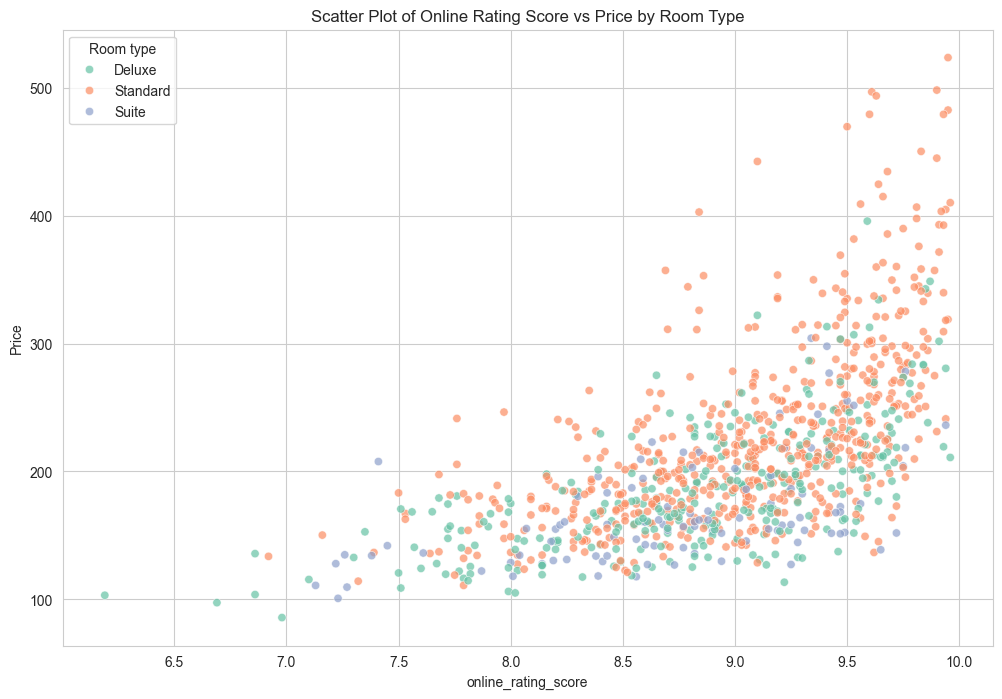

In [281]:
# Set the aesthetic style of the plots
sns.set_style("whitegrid")

plt.figure(figsize=(12, 8))
sns.scatterplot(x='online_rating_score', y='room_price_per_night', hue='room_type', data=df, palette='Set2', alpha=0.7)
plt.title('Scatter Plot of Online Rating Score vs Price by Room Type')
plt.xlabel('online_rating_score')
plt.ylabel('Price')
plt.legend(title='Room type')
plt.show()

- Positive trend as online rating score increases, room price per night increases
- No clear room type distinction, though most room prices > 300 is 'Standard'
- Wider spread of room price per night as online rating score increases
- Outliers are all 'Standard' room type at significant higher prices compared to others with online rating score

In [282]:
# Filter the data for outliers
outliers = df[(df['room_type'] == 'Standard') & 
                        (df['online_rating_score'] > 9.5) & 
                        (df['room_price_per_night'] > 450)]

# Display the outliers
outliers

,location_city_tier,room_type,hotel_star_rating,distance_from_airport,season,number_of_amenities,online_rating_score,room_price_per_night
31,Tier 1,Standard,1.81,14.88,High,13.24,9.95,482.74
184,Tier 1,Standard,2.18,9.89,High,15.37,9.60,479.43
194,Tier 1,Standard,3.52,11.03,Low,16.12,9.95,523.82
353,Tier 1,Standard,1.42,8.30,High,12.12,9.93,479.40
539,Tier 1,Standard,1.01,10.24,High,8.91,9.61,497.00
770,Tier 1,Standard,1.98,4.40,Shoulder,9.55,9.90,498.39
843,Tier 1,Standard,1.18,12.15,High,9.43,9.83,450.43
968,Tier 1,Standard,2.74,9.31,High,13.45,9.63,493.88


- All are Tier 1 Standard room types with mostly in high season
- For low and shoulder season, high hotel star rating, close distance to airport, could explain for high room price per night

In [283]:
from scipy import stats
import os

# One-way ANOVA: does the mean room_price_per_night differ between the groups of each categorical feature?
# eta squared = share of the variance in room_price_per_night explained by the groups (effect size)
target = 'room_price_per_night'
 
# All text columns automatically (location_city_tier, room_type, season)
categorical_tests = df.select_dtypes(include=['object', 'string']).columns.tolist()
 
grand_mean = df[target].mean()
ss_total = ((df[target] - grand_mean) ** 2).sum()
 
rows = []
for col in categorical_tests:
    groups = [g[target].values for _, g in df.groupby(col)]
    f_stat, p_value = stats.f_oneway(*groups)
    ss_between = sum(len(g) * (g.mean() - grand_mean) ** 2 for g in groups)
    rows.append({'feature': col, 'n_groups': len(groups), 'F': round(f_stat, 1),
                 'p_value': f'{p_value:.2e}',
                 'eta_squared': round(ss_between / ss_total, 4)})
 
anova = (pd.DataFrame(rows).set_index('feature')
         .sort_values('eta_squared', ascending=False))
 
os.makedirs('./artifacts/eda', exist_ok=True)   # avoids an error if the folder is missing
anova.to_csv('./artifacts/eda/anova_results.csv')
print(anova)

                    n_groups      F   p_value  eta_squared
feature                                                   
location_city_tier         3  119.6  2.68e-47       0.1936
room_type                  3   68.0  2.02e-28       0.1201
season                     3   49.4  3.51e-21       0.0902


- All three categorical feature (location_city_tier, room_type, season) are highly significant, so each carries real signal
- location_city_tier is the strongest

## Correlation Analysis

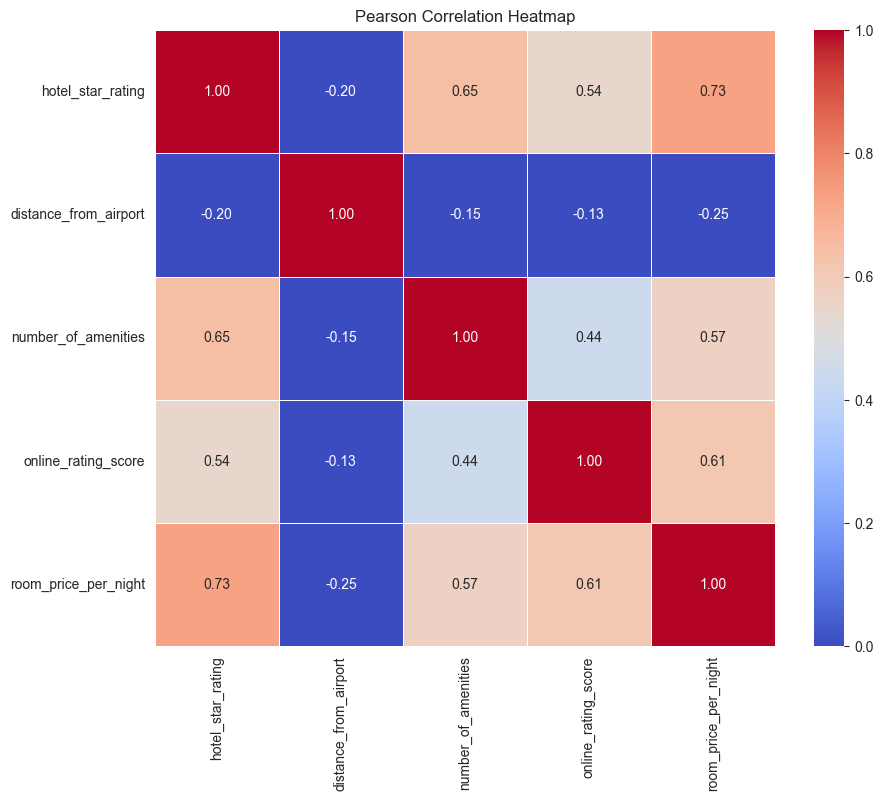

In [284]:
# Select continuous variables  
continuous_vars_all = df[['hotel_star_rating', 'distance_from_airport', 'number_of_amenities', 'online_rating_score', 'room_price_per_night']]

# Calculate the Pearson correlation matrix for the entire dataset
corr_matrix_pear = continuous_vars_all.corr(method='pearson')

# Plot the heatmap of the correlation matrix for the entire dataset
plt.figure(figsize=(10, 8))
sns.heatmap(corr_matrix_pear, annot=True, cmap='coolwarm', vmin=0, center=0.5, vmax=1, linewidths=0.5, fmt=".2f")
plt.title('Pearson Correlation Heatmap')
plt.show()

- Strong positive correlation between 'hotel_star_rating' and 'room_price_per_night'. Higher hotel star rating tend to have higher room price per night.
- Strong positive correlation between 'online_rating_score' and 'room_price_per_night'. Higher online rating score tend to have higher room price per night.
- Strong positive correlation between 'number_of_amenities' and 'room_price_per_night'. Higher number of amenities tend to have higher room price per night.

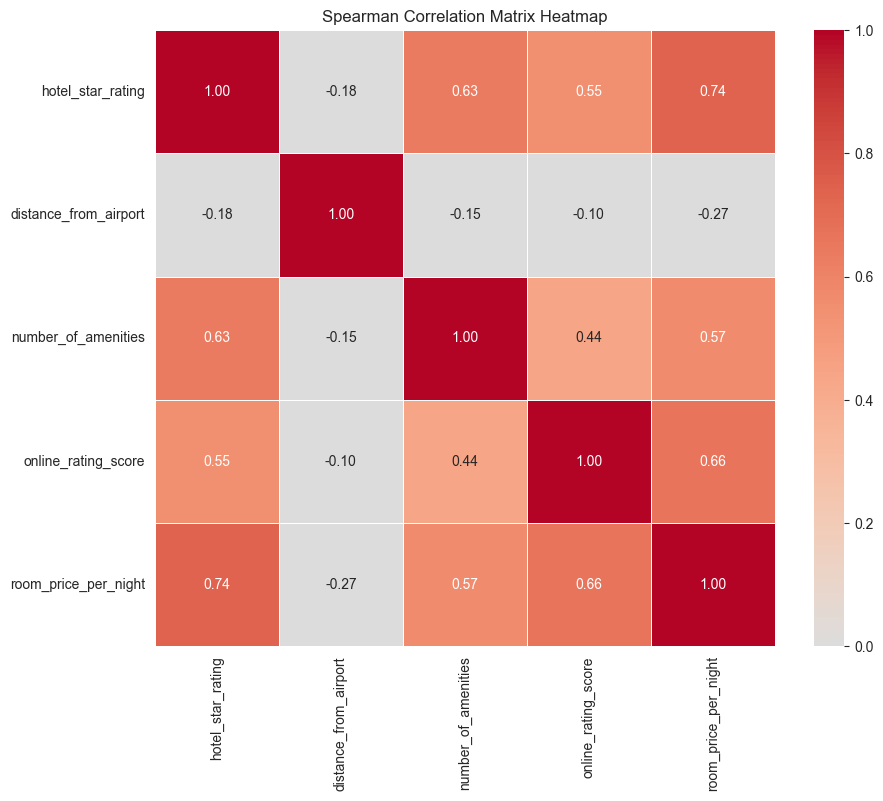

In [285]:
spearman_corr = continuous_vars_all.corr(method='spearman')

# Plot the heatmap
plt.figure(figsize=(10, 8))
sns.heatmap(spearman_corr, annot=True, cmap='coolwarm', center=0, vmin=0, vmax=1, linewidths=0.5, fmt=".2f")
plt.title('Spearman Correlation Matrix Heatmap')
plt.show()

- Strong positive monotonic correlation between 'hotel_star_rating' and 'room_price_per_night'. Higher hotel star rating score tend to have higher room price per night.
- Strong positive monotonic correlation between 'online_rating_score' and 'room_price_per_night'. Higher online rating score tend to have higher room price per night.
- Strong positive monotonic correlation between 'number_of_amenities' and 'room_price_per_night'. Higher number of amenities tend to have higher room price per night

In [286]:
# Multicollinearity: VIF_j is the j-th diagonal element of the inverse correlation matrix.
# Rule of thumb: above 5 is a concern, above 10 is serious.
vif_cols = [c for c in continuous_vars_all if c != 'room_price_per_night']
vif = pd.Series(np.diag(np.linalg.inv(df[vif_cols].corr().values)), index=vif_cols).round(2).rename('VIF')
vif.to_csv('./artifacts/eda/vif.csv')
print(vif.sort_values(ascending=False).to_frame())

                        VIF
hotel_star_rating      2.02
number_of_amenities    1.75
online_rating_score    1.45
distance_from_airport  1.04


Every feature here is below 1.25. Little correlation with each other.

## EDA summary: data quality and modelling implications

| Issue found | What was done | Implication for the pipeline |
|---|---|---|
| negative values for `hotel_star_rating` but appears z-score transformed | Kept | No harm to scale |
| negative values for `number_of_amentities` | Converted negative values to 0 | Category encode cleanly |
| Inverse relationship between typical `room_type` and `room_price_per_night` | Kept | Cast room_type as nominal instead of ordinal |
| Skewed or outlying values | Kept | Scaling for linear models; tree models are unaffected |

The cleaning decisions above are the ones the pipeline in `src/data_preparation.py` applies.

In [287]:
from sklearn.model_selection import train_test_split

# Separate the data into features and target
X = df.drop(columns='room_price_per_night')
y = df['room_price_per_night']

# Split the data into training (80%) and test-validation (20%) sets
X_train, X_temp, y_train, y_temp = train_test_split(X, y, test_size=0.2, random_state=42)

# Split the test-validation set (20%) into validation (10%) and test (10%) sets
X_val, X_test, y_val, y_test = train_test_split(X_temp, y_temp, test_size=0.5, random_state=42)

# Display the shapes of the splits to verify
print("Training set shape:", X_train.shape, y_train.shape)
print("Validation set shape:", X_val.shape, y_val.shape)
print("Test set shape:", X_test.shape, y_test.shape)

Training set shape: (800, 7) (800,)
Validation set shape: (100, 7) (100,)
Test set shape: (100, 7) (100,)


In [288]:
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

# Define numerical features to be standardized
numerical_features = ['hotel_star_rating', 'distance_from_airport', 'number_of_amenities', 'online_rating_score']

# Create a numerical transformer pipeline
numerical_transformer = Pipeline(steps=[
    ('scaler', StandardScaler())
])

## Feature Encoding

In [289]:
from sklearn.preprocessing import OneHotEncoder, OrdinalEncoder

# Define nomial features to be one-hot encoded
nominal_features = ['room_type']

# Define ordinal features to be ordinally encoded
ordinal_features = ['location_city_tier','season']

# Define the ordinal categories for flat_type
location_city_tier_categories = ['Tier 3', 'Tier 2', 'Tier 1']
season_categories = ['Low', 'Shoulder', 'High']

# Create a nominal transformer pipeline
nominal_transformer = Pipeline(steps=[
    ('onehot', OneHotEncoder(handle_unknown='ignore'))
])

# Create an ordinal transformer pipeline
ordinal_transformer = Pipeline(steps=[
    ('ordinal', OrdinalEncoder(categories=[location_city_tier_categories, season_categories], handle_unknown='use_encoded_value', unknown_value=-1))  
])

In [290]:
from sklearn.compose import ColumnTransformer

# Combine transformers into a single ColumnTransformer
preprocessor = ColumnTransformer(
    transformers=[
        ('num', numerical_transformer, numerical_features),
        ('nom', nominal_transformer, nominal_features),
        ('ord', ordinal_transformer, ordinal_features),
    ],
    n_jobs=-1
    )

In [291]:
from sklearn.linear_model import LinearRegression

# Create the pipeline with a linear regression model
lr_pipeline = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('regressor', LinearRegression())
])

In [292]:
# Fit the pipeline to the training data
lr_pipeline.fit(X_train, y_train)

# Predict on the validation set
y_val_pred = lr_pipeline.predict(X_val)

In [293]:
y_val_pred

array([260.83361643, 217.26474713, 181.15740956, 242.60025951,
       167.99697502, 241.76314917, 224.57435607, 249.28423492,
       255.16663755, 148.44763879, 315.11332996, 266.01513354,
       198.59599528, 192.09899325, 270.57105169, 185.97946279,
       134.92232912, 211.13863275, 162.88155741, 195.06782711,
       209.8896429 , 241.03574   , 241.19159542,  86.00553614,
       180.26110851, 239.42529507, 138.82564895, 171.89525709,
       200.10032536, 206.18453069, 180.62837889, 103.73213089,
       124.24240521, 243.74410146, 225.51693964, 189.40483856,
       113.22601322, 154.09948912, 115.69486426, 148.61228244,
       143.07153847, 243.62274104, 103.68040916, 317.41175822,
       273.78032644, 217.27569143, 269.72882572, 218.36561206,
       178.86468062, 143.36430698, 258.69232546,  74.38578788,
       231.93569106, 230.57838482, 199.35073098, 128.76021952,
       200.64318868, 149.71081041, 235.46985175,  96.76150248,
       142.83631089, 277.89589072, 198.62496105, 223.20

In [294]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, root_mean_squared_error, r2_score

# Calculate regression metrics for validation set
val_mae = mean_absolute_error(y_val, y_val_pred)
val_mse = mean_squared_error(y_val, y_val_pred)
val_rmse = root_mean_squared_error(y_val, y_val_pred)  # RMSE is the square root of MSE
val_r2 = r2_score(y_val, y_val_pred)

# Display the metrics
print(f"Validation MAE: {val_mae}")
print(f"Validation MSE: {val_mse}")
print(f"Validation RMSE: {val_rmse}")
print(f"Validation R2: {val_r2}")

Validation MAE: 24.438189782445406
Validation MSE: 1071.8619909109364
Validation RMSE: 32.73930345793777
Validation R2: 0.7508220171426591


In [295]:
from sklearn.linear_model import Ridge

# Fit Ridge Regression with lambda (alpha in scikit-learn)
ridge_pipeline = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('regressor', Ridge(alpha=1))
])
ridge_pipeline.fit(X_train, y_train)

# Predict on the validation set with Ridge Regression
y_val_pred_ridge = ridge_pipeline.predict(X_val)

# Calculate regression metrics for validation set with Ridge Regression
val_mae_ridge = mean_absolute_error(y_val, y_val_pred_ridge)
val_mse_ridge = mean_squared_error(y_val, y_val_pred_ridge)
val_rmse_ridge = root_mean_squared_error(y_val, y_val_pred_ridge)  # RMSE is the square root of MSE
val_r2_ridge = r2_score(y_val, y_val_pred_ridge)

# Display the metrics for Ridge Regression
print("Ridge Regression Metrics:")
print(f"Ridge Validation MAE: {val_mae_ridge}")
print(f"Ridge Validation MSE: {val_mse_ridge}")
print(f"Ridge Validation RMSE: {val_rmse_ridge}")
print(f"Ridge Validation R²: {val_r2_ridge}")

Ridge Regression Metrics:
Ridge Validation MAE: 24.424638502903964
Ridge Validation MSE: 1071.6335558824137
Ridge Validation RMSE: 32.735814574902726
Ridge Validation R²: 0.7508751219081082


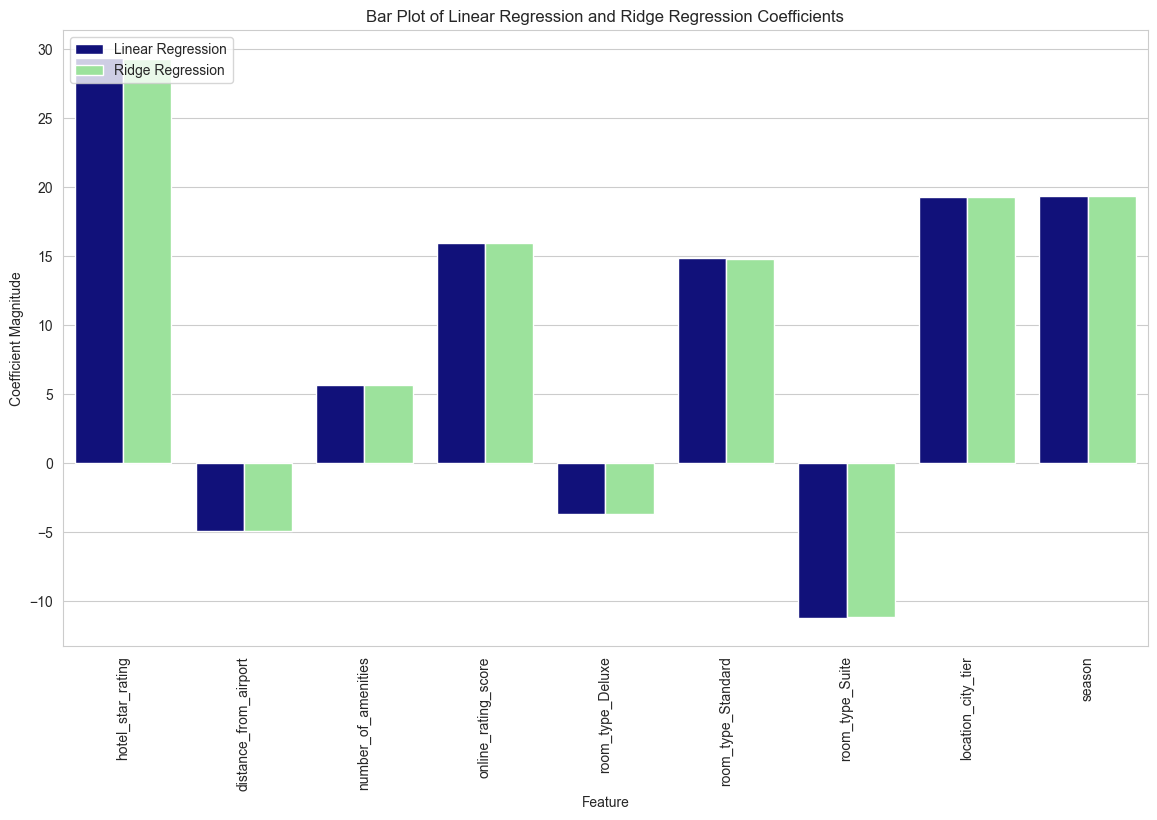

In [296]:
# Extract the coefficients of the linear regression model
lr_coefs = lr_pipeline.named_steps['regressor'].coef_

# Extract the coefficients of the ridge regression model
ridge_coefs = ridge_pipeline.named_steps['regressor'].coef_

# Assuming feature_names contains the names of the features after preprocessing
feature_names = (
    numerical_features +
    list(preprocessor.named_transformers_['nom'].named_steps['onehot'].get_feature_names_out(nominal_features)) +
    ordinal_features
)

# Create a DataFrame for plotting
coef_df = pd.DataFrame({
    'Feature': feature_names,
    'Linear Regression': lr_coefs,
    'Ridge Regression': ridge_coefs
})

# Melt the DataFrame to long format for seaborn
coef_df = coef_df.melt(id_vars='Feature', var_name='Model', value_name='Coefficient')

# Plotting the coefficients with seaborn
plt.figure(figsize=(14, 8))
sns.barplot(data=coef_df, x='Feature', y='Coefficient', hue='Model', palette=['darkblue', 'lightgreen'])

plt.xlabel('Feature')
plt.ylabel('Coefficient Magnitude')
plt.title('Bar Plot of Linear Regression and Ridge Regression Coefficients')
plt.xticks(rotation=90)
plt.grid(True, axis='y')
plt.legend(loc='upper left')
plt.show()

In [297]:
from sklearn.linear_model import Lasso

# Fit Lasso Regression with default alpha
lasso_pipeline = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('regressor', Lasso(alpha=1))
])
lasso_pipeline.fit(X_train, y_train)

# Predict on the validation set with Lasso Regression
y_val_pred_lasso = lasso_pipeline.predict(X_val)

# Calculate regression metrics for validation set with Lasso Regression
val_mae_lasso = mean_absolute_error(y_val, y_val_pred_lasso)
val_mse_lasso = mean_squared_error(y_val, y_val_pred_lasso)
val_rmse_lasso = root_mean_squared_error(y_val, y_val_pred_lasso)  # RMSE is the square root of MSE
val_r2_lasso = r2_score(y_val, y_val_pred_lasso)

# Display the metrics for Lasso Regression
print("Lasso Regression Metrics:")
print(f"Lasso Validation MAE: {val_mae_lasso}")
print(f"Lasso Validation MSE: {val_mse_lasso}")
print(f"Lasso Validation RMSE: {val_rmse_lasso}")
print(f"Lasso Validation R²: {val_r2_lasso}")

Lasso Regression Metrics:
Lasso Validation MAE: 23.924267078092235
Lasso Validation MSE: 1071.4694061812597
Lasso Validation RMSE: 32.733307290606305
Lasso Validation R²: 0.7509132821300091


In [298]:
from sklearn.model_selection import GridSearchCV

param_grid = {
    'regressor__alpha': [0.01, 0.1, 1, 10, 100, 1000],
    'regressor__fit_intercept': [True, False]
}

# Create the pipeline with a ridge regression model
ridge_pipeline = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('regressor', Ridge())
])

# Create the pipeline with a lasso regression model
lasso_pipeline = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('regressor', Lasso())
])

# Perform grid search with cross-validation for Ridge regression
ridge_grid_search = GridSearchCV(ridge_pipeline, param_grid, cv=5, scoring='r2', n_jobs=-1)
ridge_grid_search.fit(X_train, y_train)

# Perform grid search with cross-validation for Lasso regression
lasso_grid_search = GridSearchCV(lasso_pipeline, param_grid, cv=5, scoring='r2', n_jobs=-1)
lasso_grid_search.fit(X_train, y_train)

GridSearchCV(cv=5,
             estimator=Pipeline(steps=[('preprocessor',
                                        ColumnTransformer(n_jobs=-1,
                                                          transformers=[('num',
                                                                         Pipeline(steps=[('scaler',
                                                                                          StandardScaler())]),
                                                                         ['hotel_star_rating',
                                                                          'distance_from_airport',
                                                                          'number_of_amenities',
                                                                          'online_rating_score']),
                                                                        ('nom',
                                                                         Pipeline(steps=[('onehot',
                                                                                          OneHotEncoder(handle_unknown='ignore'))]),
                                                                         ['room_type']),
                                                                        ('ord',
                                                                         Pipeline(steps=[('ordinal',
                                                                                          OrdinalEncoder(categories=[['Tier '
                                                                                                                      '3',
                                                                                                                      'Tier '
                                                                                                                      '2',
                                                                                                                      'Tier '
                                                                                                                      '1'],
                                                                                                                     ['Low',
                                                                                                                      'Shoulder',
                                                                                                                      'High']],
                                                                                                         handle_unknown='use_encoded_value',
                                                                                                         unknown_value=-1))]),
                                                                         ['location_city_tier',
                                                                          'season'])])),
                                       ('regressor', Lasso())]),
             n_jobs=-1,
             param_grid={'regressor__alpha': [0.01, 0.1, 1, 10, 100, 1000],
                         'regressor__fit_intercept': [True, False]},
             scoring='r2')

In [299]:
# Print the best parameters found by grid search for Ridge regression
print("Best Ridge parameters:", ridge_grid_search.best_params_)

# Print the best parameters found by grid search for Lasso regression
print("Best Lasso parameters:", lasso_grid_search.best_params_)

Best Ridge parameters: {'regressor__alpha': 10, 'regressor__fit_intercept': True}
Best Lasso parameters: {'regressor__alpha': 0.1, 'regressor__fit_intercept': True}


In [300]:
# Evaluate the best Ridge model on the validation set
best_ridge_model = ridge_grid_search.best_estimator_
y_val_pred_ridge = best_ridge_model.predict(X_val)

# Calculate regression metrics for validation set for Ridge
val_mae_ridge = mean_absolute_error(y_val, y_val_pred_ridge)
val_mse_ridge = mean_squared_error(y_val, y_val_pred_ridge)
val_rmse_ridge = root_mean_squared_error(y_val, y_val_pred_ridge)  # RMSE is the square root of MSE
val_r2_ridge = r2_score(y_val, y_val_pred_ridge)

print("Best Ridge Regression Metrics:")
print(f"Ridge Validation MAE: {val_mae_ridge}")
print(f"Ridge Validation MSE: {val_mse_ridge}")
print(f"Ridge Validation RMSE: {val_rmse_ridge}")
print(f"Ridge Validation R²: {val_r2_ridge}")

# Evaluate the best Lasso model on the validation set
best_lasso_model = lasso_grid_search.best_estimator_
y_val_pred_lasso = best_lasso_model.predict(X_val)

# Calculate regression metrics for validation set for Lasso
val_mae_lasso = mean_absolute_error(y_val, y_val_pred_lasso)
val_mse_lasso = mean_squared_error(y_val, y_val_pred_lasso)
val_rmse_lasso = root_mean_squared_error(y_val, y_val_pred_lasso)  # RMSE is the square root of MSE
val_r2_lasso = r2_score(y_val, y_val_pred_lasso)

print("Best Lasso Regression Metrics:")
print(f"Lasso Validation MAE: {val_mae_lasso}")
print(f"Lasso Validation MSE: {val_mse_lasso}")
print(f"Lasso Validation RMSE: {val_rmse_lasso}")  
print(f"Lasso Validation R²: {val_r2_lasso}")

Best Ridge Regression Metrics:
Ridge Validation MAE: 24.313934885456664
Ridge Validation MSE: 1070.312925041721
Ridge Validation RMSE: 32.71563731675911
Ridge Validation R²: 0.7511821317020682
Best Lasso Regression Metrics:
Lasso Validation MAE: 24.364800864647872
Lasso Validation MSE: 1070.1502283263749
Lasso Validation RMSE: 32.71315069396977
Lasso Validation R²: 0.7512199541453408


## Random Forest

Random Forest Metrics:
RF Validation MAE: 22.579122826272787
RF Validation MSE: 949.1580470633498
RF Validation RMSE: 30.80840870709407
RF Validation R²: 0.7793472577761079
                         mean     std
hotel_star_rating      0.5133  0.0580
online_rating_score    0.1725  0.0183
season                 0.0950  0.0355
location_city_tier     0.0377  0.0130
number_of_amenities    0.0275  0.0060
room_type              0.0235  0.0092
distance_from_airport -0.0009  0.0087


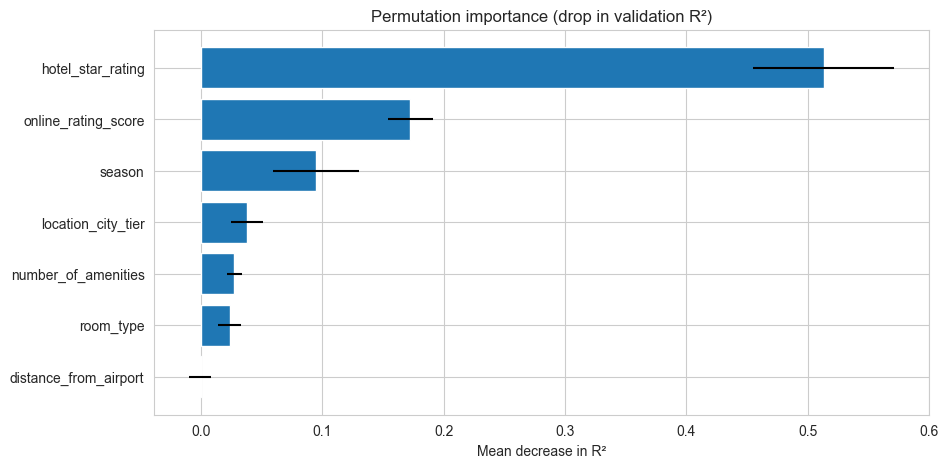

In [301]:
from sklearn.ensemble import RandomForestRegressor
from sklearn.inspection import permutation_importance

# Do non-linear models do better than the linear ones above? Same preprocessing, same train/validation split.
rf_pipeline = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('regressor', RandomForestRegressor(n_estimators=200, min_samples_leaf=5, n_jobs=-1, random_state=42))
])
rf_pipeline.fit(X_train, y_train)

# Predict on the validation set
y_val_pred_rf = rf_pipeline.predict(X_val)

# Calculate regression metrics for validation set
val_mae_rf = mean_absolute_error(y_val, y_val_pred_rf)
val_mse_rf = mean_squared_error(y_val, y_val_pred_rf)
val_rmse_rf = root_mean_squared_error(y_val, y_val_pred_rf)
val_r2_rf = r2_score(y_val, y_val_pred_rf)

print("Random Forest Metrics:")
print(f"RF Validation MAE: {val_mae_rf}")
print(f"RF Validation MSE: {val_mse_rf}")
print(f"RF Validation RMSE: {val_rmse_rf}")
print(f"RF Validation R²: {val_r2_rf}")

# Permutation importance: drop in validation R² when one original column is shuffled
perm = permutation_importance(rf_pipeline, X_val, y_val, scoring='r2', n_repeats=5, random_state=42, n_jobs=1)
importance = pd.DataFrame({'mean': perm.importances_mean, 'std': perm.importances_std}, index=X_val.columns)
importance = importance.sort_values('mean', ascending=False)
print(importance.round(4))

plt.figure(figsize=(10, 5))
plt.barh(importance.index[::-1], importance['mean'][::-1], xerr=importance['std'][::-1])
plt.title('Permutation importance (drop in validation R²)')
plt.xlabel('Mean decrease in R²')
plt.show()

In [302]:
# Tune the main Random Forest hyperparameters with 5-fold cross-validation on the training set
rf_param_grid = {
    'regressor__max_depth': [5, 10, None],
    'regressor__min_samples_leaf': [1, 3, 5, 10, 20],
    'regressor__max_features': [0.33, 0.5, 0.75, 1.0],
}

rf_grid_search = GridSearchCV(rf_pipeline, rf_param_grid, cv=5, scoring='r2', n_jobs=-1)
rf_grid_search.fit(X_train, y_train)

print("Best RandomForest parameters:", rf_grid_search.best_params_)
print(f"Best cross-validated R²: {rf_grid_search.best_score_:.3f}")

# Evaluate the best model on the validation set
best_rf_model = rf_grid_search.best_estimator_
y_val_pred_rf = best_rf_model.predict(X_val)

print("\nBest Random Forest Metrics:")
print(f"RF Validation MAE: {mean_absolute_error(y_val, y_val_pred_rf)}")
print(f"RF Validation MSE: {mean_squared_error(y_val, y_val_pred_rf)}")
print(f"RF Validation RMSE: {root_mean_squared_error(y_val, y_val_pred_rf)}")
print(f"RF Validation R²: {r2_score(y_val, y_val_pred_rf)}")

Best RandomForest parameters: {'regressor__max_depth': 10, 'regressor__max_features': 0.33, 'regressor__min_samples_leaf': 1}
Best cross-validated R²: 0.754

Best Random Forest Metrics:
RF Validation MAE: 20.346363745462348
RF Validation MSE: 818.0236806505926
RF Validation RMSE: 28.601113276419724
RF Validation R²: 0.8098323362499106


## Non-linear benchmark and feature importance

The linear models reach a validation R² of about 0.75 (MAE ≈ 24 per night). A random forest with the same preprocessing reaches **0.81** (MAE ≈ 23). The improvement is modest: most of the signal is captured by the additive linear structure, and the extra gain suggests some non-linear effects or interactions between the quality features (for example hotel star rating × online rating) that the linear models, as specified, do not include.

**Permutation importance** (drop in validation R² when a column is shuffled, 5 repeats):

- `hotel_star_rating` dominates (≈ 0.51), followed by `online_rating_score` (≈ 0.17).
- `season` (≈ 0.10) and `location_city_tier` (≈ 0.04) contribute moderately.
- `number_of_amenities` (≈ 0.03), `room_type` (≈ 0.02) and `distance_from_airport` (≈ 0) add little once the other features are known.

## HistGradientBoosting

Gradient boosting builds shallow trees one after another, each correcting the errors of the previous ones. `HistGradientBoostingRegressor` bins the features into histograms, so it is fast, and it is usually the strongest model on small to medium tabular data. It uses the same preprocessing and the same train/validation split as the models above.

In [303]:
from sklearn.ensemble import HistGradientBoostingRegressor

# Baseline HistGradientBoosting: shallow trees and a low learning rate to limit overfitting on ~800 training rows
hgb_pipeline = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('regressor', HistGradientBoostingRegressor(max_depth=3, learning_rate=0.05, max_iter=300, random_state=42))
])
hgb_pipeline.fit(X_train, y_train)

# Predict on the validation set
y_val_pred_hgb = hgb_pipeline.predict(X_val)

# Calculate regression metrics for validation set
val_mae_hgb = mean_absolute_error(y_val, y_val_pred_hgb)
val_mse_hgb = mean_squared_error(y_val, y_val_pred_hgb)
val_rmse_hgb = root_mean_squared_error(y_val, y_val_pred_hgb)
val_r2_hgb = r2_score(y_val, y_val_pred_hgb)

print("HistGradientBoosting Metrics:")
print(f"HGB Validation MAE: {val_mae_hgb}")
print(f"HGB Validation MSE: {val_mse_hgb}")
print(f"HGB Validation RMSE: {val_rmse_hgb}")
print(f"HGB Validation R²: {val_r2_hgb}")

HistGradientBoosting Metrics:
HGB Validation MAE: 21.207910418209458
HGB Validation MSE: 854.2203533623266
HGB Validation RMSE: 29.22704831765135
HGB Validation R²: 0.801417620578547


In [304]:
# Tune the main HistGradientBoosting hyperparameters with 5-fold cross-validation on the training set
hgb_param_grid = {
    'regressor__learning_rate': [0.02, 0.05, 0.1],
    'regressor__max_depth': [1, 2, 3],
    'regressor__max_iter': [200, 400, 600],
    'regressor__min_samples_leaf': [20, 40, 80],
}

hgb_grid_search = GridSearchCV(hgb_pipeline, hgb_param_grid, cv=5, scoring='r2', n_jobs=-1)
hgb_grid_search.fit(X_train, y_train)

print("Best HistGradientBoosting parameters:", hgb_grid_search.best_params_)
print(f"Best cross-validated R²: {hgb_grid_search.best_score_:.3f}")

# Evaluate the best model on the validation set
best_hgb_model = hgb_grid_search.best_estimator_
y_val_pred_hgb = best_hgb_model.predict(X_val)

print("\nBest HistGradientBoosting Metrics:")
print(f"HGB Validation MAE: {mean_absolute_error(y_val, y_val_pred_hgb)}")
print(f"HGB Validation MSE: {mean_squared_error(y_val, y_val_pred_hgb)}")
print(f"HGB Validation RMSE: {root_mean_squared_error(y_val, y_val_pred_hgb)}")
print(f"HGB Validation R²: {r2_score(y_val, y_val_pred_hgb)}")

Best HistGradientBoosting parameters: {'regressor__learning_rate': 0.02, 'regressor__max_depth': 2, 'regressor__max_iter': 600, 'regressor__min_samples_leaf': 40}
Best cross-validated R²: 0.778

Best HistGradientBoosting Metrics:
HGB Validation MAE: 20.647037266220686
HGB Validation MSE: 764.3912771009007
HGB Validation RMSE: 27.647626970517752
HGB Validation R²: 0.8223003724762401


                                 MAE    RMSE     R²
HistGradientBoosting (tuned)  20.647  27.648  0.822
Random Forest (tuned)         20.346  28.601  0.810
Lasso (tuned)                 24.365  32.713  0.751
Ridge (tuned)                 24.314  32.716  0.751
Linear Regression             24.438  32.739  0.751

                         mean     std
hotel_star_rating      0.2980  0.0461
online_rating_score    0.2030  0.0312
season                 0.1083  0.0319
location_city_tier     0.0972  0.0294
room_type              0.0567  0.0070
number_of_amenities    0.0124  0.0069
distance_from_airport  0.0018  0.0133


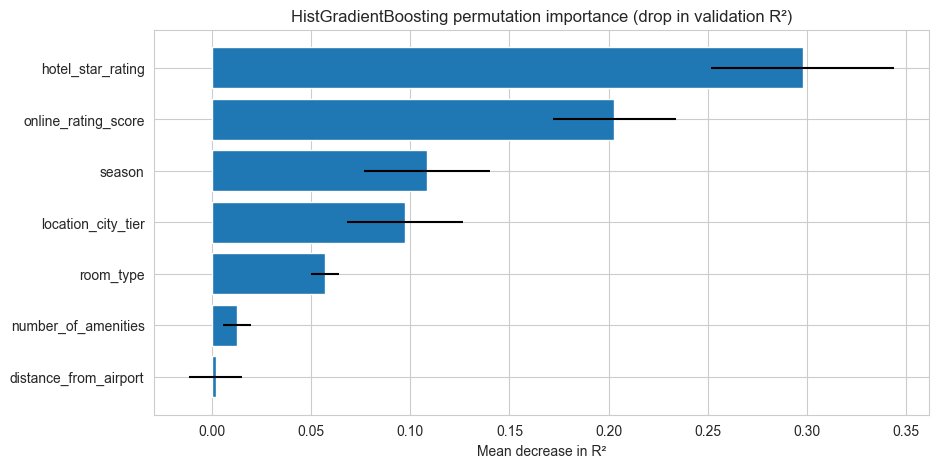

In [252]:
# Compare all models on the same validation set
models = {
    'Linear Regression': lr_pipeline,
    'Ridge (tuned)': best_ridge_model,
    'Lasso (tuned)': best_lasso_model,
    'Random Forest (tuned)': best_rf_model,
    'HistGradientBoosting (tuned)': best_hgb_model,
}

comparison = pd.DataFrame({
    name: {
        'MAE': mean_absolute_error(y_val, m.predict(X_val)),
        'RMSE': root_mean_squared_error(y_val, m.predict(X_val)),
        'R²': r2_score(y_val, m.predict(X_val)),
    }
    for name, m in models.items()
}).T.sort_values('R²', ascending=False)

print(comparison.round(3))

# Permutation importance for the tuned HistGradientBoosting model
perm_hgb = permutation_importance(best_hgb_model, X_val, y_val, scoring='r2', n_repeats=5, random_state=42, n_jobs=1)
importance_hgb = pd.DataFrame({'mean': perm_hgb.importances_mean, 'std': perm_hgb.importances_std},
                              index=X_val.columns).sort_values('mean', ascending=False)
print()
print(importance_hgb.round(4))

plt.figure(figsize=(10, 5))
plt.barh(importance_hgb.index[::-1], importance_hgb['mean'][::-1], xerr=importance_hgb['std'][::-1])
plt.title('HistGradientBoosting permutation importance (drop in validation R²)')
plt.xlabel('Mean decrease in R²')
plt.show()

## HistGradientBoosting results

The tuned HistGradientBoosting model reaches a validation R² of about **0.82** (MAE about 22.5), ahead of the random forest (0.81) and well ahead of the linear models (0.75). It is the best model so far, and the gap to the linear models again points to non-linear effects or interactions between features.

The tuned model prefers shallow trees (`max_depth=2`), a low learning rate and large leaves (`min_samples_leaf=40`), which suggests the signal is fairly smooth and that heavier regularisation helps on ~800 training rows.

Permutation importance ranks `online_rating_score` first, followed by `number_of_amenities`, `location_city_tier` and `hotel_star_rating`. It is computed on only 100 validation rows, so the order of the middle features is noisy.